# Benchmarking a qubit: T1, T2*, and T2

## The problem

Every circuit in this course runs against a clock. A qubit is a physical object that slowly loses what we stored in it, and the longer a circuit takes, the more is lost. Before running anything on a device, ask how long a qubit keeps its state. Three numbers answer that. They are among the first entries on the **calibration page** of a quantum computer: a web page that lists, for each qubit of the device, measured values such as these times and the gate and read-out errors, refreshed after each routine calibration. `ibm_rensselaer` is the IBM device used in this course, and it has such a page.

Recall the two things a qubit holds: a **bit** (is it $|0\rangle$ or $|1\rangle$?) and a **phase** (the relative angle between the amplitudes of $|0\rangle$ and $|1\rangle$, which is what interference uses). Each can be lost. The words used below are explained in the bullets, and the *Terms* table at the end lists them again.

- **T1, relaxation time.** The state $|0\rangle$ is the lower-energy state of the qubit, and $|1\rangle$ is the higher-energy one. A system left alone drifts toward lower energy, so a qubit in $|1\rangle$ eventually falls to $|0\rangle$. The stored bit flips by itself. T1 is the time scale of that flip.
- **T2\*, dephasing time seen by a Ramsey experiment.** A *Ramsey experiment* has three steps: prepare $|+\rangle = (|0\rangle+|1\rangle)/\sqrt2$, wait a time $t$, and measure $\langle X\rangle$ (the expectation value of the Pauli operator $X$). A qubit in a superposition has a phase, and the phase angle grows steadily with time, like the angle of a rotating arrow. The rate is set by the **qubit frequency**, the energy difference between $|1\rangle$ and $|0\rangle$ written as a frequency. The qubit frequency drifts a little because of the surroundings, and it differs from one run to the next. After a wait $t$, each run therefore has collected a different phase, and the average over many runs shrinks toward zero. The bit is fine. The *superposition* is lost. T2\* is the time scale of that loss.
- **T2, dephasing time after an echo.** Much of the wandering is slow: constant during one run, different from run to run. A single bit flip ($X$) in the middle of the wait cancels everything that is constant, and the argument takes two lines. Say the qubit has a constant frequency error that adds the phase $\varphi$ in each half of the wait. The first half builds $\varphi$. The flip exchanges $|0\rangle$ and $|1\rangle$, which turns the phase $+\varphi$ into $-\varphi$ (the state $|1\rangle + e^{i\varphi}|0\rangle$ equals $e^{i\varphi}(|0\rangle + e^{-i\varphi}|1\rangle)$, and a global factor changes nothing). The second half adds $+\varphi$ again, so the total is $-\varphi + \varphi = 0$. What an echo cannot cancel is the fast noise, which changes within a run, and T2 is the time scale of what remains.

All three are measured the same way: prepare a state, wait for a delay $t$, measure one observable, and repeat for many delays. The result is a decay curve. We do not read a time off the plot directly. We fit a model curve to the data, and **the time is one of the fit parameters** (Step 4).

The three times obey $T_2^* \le T_2 \le 2\,T_1$. The first inequality holds because the echo removes the slow noise and adds none. The second is derived at the end of Step 4.

## The workflow

| Step | What it does | Code |
|---|---|---|
| 1. Operator | The observable each experiment measures, and the decay model we fit | `ops.py` |
| 2. Encoding | Build the delay circuits and round delays to what the hardware can run | `encoding.py` |
| 3. Execution | Run every delay of every experiment as one job | `execution.py` |
| 4. Analysis | Fit the curves, plot the fits, read off the times | `analysis.py` |

The same steps run from the command line with `python benchmarking/main.py`, started in `../scripts/`. The code lives in `../scripts/benchmarking/` and is imported below. Times are in microseconds.

## Setup

By default this notebook runs on the **Aer simulator**: a program on an ordinary computer that mimics a quantum device, with noise that we choose. We choose $T_1 = 100\,\mu$s, $T_2 = 70\,\mu$s (both defined under [The problem](#the-problem)), a slow frequency noise that makes $T_2^*$ shorter than $T_2$, and a **read-out error** of 2% to 4%. A read-out error is a wrong measurement result: here a true 0 is read as 1 with probability 2%, and a true 1 is read as 0 with probability 4%. Because we know the answers, we can check the fits against them. Set `backend_name = "ibm_rensselaer"` to measure a real qubit instead.

The four helper modules need not be read to follow this notebook.

- `ops` holds the observables, the decay models, and the noise settings of the simulator.
- `encoding` builds the delay circuits and rounds delays to what hardware accepts. `execution` runs them and collects the numbers.
- `analysis` fits the curves and draws the tables and figures.

The settings:

- `qubit`: the physical qubit to measure on hardware. Ignored on the simulator.
- `points`: delays per experiment. More points give a better fit and cost more circuits.
- `precision`: target **standard error** of each expectation value, the typical size of the random scatter of an estimate around its true value. An expectation value is the average of many $\pm1$ answers, one per **shot** (one run of the circuit). The standard error of an average of $N$ shots is about $1/\sqrt N$, so `precision = 0.02` needs about $1/0.02^2 = 2500$ shots. On hardware it sets the shots. On the simulator it sets the size of the added noise.
- `t_max`: the longest delay of each experiment. A good range runs to about three **decay times**. A decay time is the $\tau$ of Step 1: the time in which the decaying part of a curve falls to $1/e \approx 37\%$ of its start. After $3\tau$ about $e^{-3} \approx 5\%$ is left. On hardware you do not know the times before you measure them, so run once with a wide range, read the fit, and run again with the range centered on the answer.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from qiskit.quantum_info import Statevector

# The benchmarking code lives in ../scripts/benchmarking.
# Run this notebook from its own folder (the Jupyter default).
sys.path.insert(0, str(Path("../scripts/benchmarking").resolve()))

import analysis
import encoding as enc
import execution
import ops

%matplotlib inline

backend_name = None  # None = Aer simulator, or e.g. "ibm_rensselaer"
qubit = 0  # physical qubit, hardware only
points = 41
precision = 0.02
t_max = {"t1": 300.0, "t2star": 120.0, "t2": 200.0}  # microseconds

## Step 1: The operator (what we measure)

### The observable

The Estimator returns the **expectation value** $\langle O\rangle$ of an operator $O$: the average of the answer $\pm1$ over many runs. The two operators we need are the ones that read the two things a qubit holds.

- $Z$ reads the **bit**. $\langle Z\rangle = P(0) - P(1)$, so it is $+1$ for $|0\rangle$ and $-1$ for $|1\rangle$.
- $X$ reads the **phase**. For the state $(|0\rangle + e^{i\varphi}|1\rangle)/\sqrt2$ it gives $\langle X\rangle = \cos\varphi$. Derivation: $X$ swaps the two amplitudes, so $\langle X\rangle = \langle\psi|X|\psi\rangle$ is the sum of the two cross terms, $\tfrac12\left(e^{i\varphi} + e^{-i\varphi}\right) = \cos\varphi$. It is $+1$ when the two amplitudes are in phase ($\varphi = 0$), $0$ at $\varphi = 90^\circ$, and $-1$ at $180^\circ$. A phase scrambled completely, with $\varphi$ random in every run, averages to $0$.

The two experiment names map to observables through `ops.observable`: `"t1"` measures $Z$, and `"t2star"` and `"t2"` measure $X$. The table shows what each experiment prepares, waits, and expects. Here $f$ is the **detuning**, a frequency that we program on purpose in the Ramsey circuit (50 kHz; the Stop-and-think section after Step 1 explains why). The gate `rz(a)` adds the phase $a$ to $|1\rangle$ relative to $|0\rangle$, so after the wait the Ramsey circuit applies `rz`$(2\pi f t)$.

| Experiment | Prepare | Wait | Measure | Expected curve |
|---|---|---|---|---|
| T1 | $\lvert1\rangle$ | $t$ | $Z$ | $\langle Z\rangle = 1 - 2e^{-t/T_1}$ |
| T2\* (Ramsey) | $\lvert+\rangle = (\lvert0\rangle+\lvert1\rangle)/\sqrt2$ | $t$, then `rz`$(2\pi f t)$ | $X$ | $\langle X\rangle = \cos(2\pi f t)\,e^{-t/T_2^*}$ |
| T2 (Hahn echo, an echo with one flip in the middle) | $\lvert+\rangle$ | $t/2$, flip, $t/2$ | $X$ | $\langle X\rangle = e^{-t/T_2}$ |

The T1 entry follows from the definition of $Z$. The probability to still be in $|1\rangle$ after a time $t$ is $P(1) = e^{-t/T_1}$, so $\langle Z\rangle = P(0) - P(1) = 1 - 2e^{-t/T_1}$. At $t=0$ this is $-1$, and for large $t$ it is $+1$.

A check on a noiseless statevector shows that the observables read what we said.

In [2]:
from qiskit import QuantumCircuit


def expectation(circuit, name):
    return Statevector(circuit).expectation_value(ops.observable(name)).real


zero = QuantumCircuit(1)
one = QuantumCircuit(1)
one.x(0)
plus = QuantumCircuit(1)
plus.h(0)
quarter = QuantumCircuit(1)
quarter.h(0)
quarter.rz(np.pi / 2, 0)  # adds a phase of 90 degrees
half = QuantumCircuit(1)
half.h(0)
half.rz(np.pi, 0)  # adds a phase of 180 degrees

# "t1" measures Z and "t2star" measures X, so these two columns are <Z> and <X>.
print(f"{'state':<26} {'<Z>':>6} {'<X>':>6}")
for label, c in [
    ("|0>", zero),
    ("|1>", one),
    ("|+>", plus),
    ("|+> with phase 90 deg", quarter),
    ("|+> with phase 180 deg", half),
]:
    print(f"{label:<26} {expectation(c, 't1'):>6.2f} {expectation(c, 't2star'):>6.2f}")

state                         <Z>    <X>
|0>                          1.00   0.00
|1>                         -1.00   0.00
|+>                          0.00   1.00
|+> with phase 90 deg        0.00   0.00
|+> with phase 180 deg       0.00  -1.00


Notice that $\langle Z\rangle$ is blind to the phase and $\langle X\rangle$ is blind to the bit of $|0\rangle$ and $|1\rangle$. That is why T1 needs $Z$ and the two dephasing times need $X$.

### The decay model

The curves are exponentials, because the loss in each short interval is proportional to what is left. In numbers: with $T_1 = 100\,\mu$s, 1% of the remaining population leaves $|1\rangle$ in each microsecond. After 100 microseconds, $0.99^{100} \approx 0.37 = 1/e$ is left. As an equation, $dP/dt = -P/T_1$, and its solution is $P(t) = e^{-t/T_1}$. We fit

$$\langle O\rangle(t) = A\,e^{-t/\tau} + B \quad\text{(T1 and T2)}, \qquad \langle X\rangle(t) = A\,e^{-t/\tau}\cos(2\pi f t + \phi) + B \quad\text{(T2*)}.$$

The time constant $\tau$ is the one we want: after one $\tau$ the decaying part has fallen to $1/e \approx 37\%$ of its start. $A$ and $B$ are **nuisance parameters**: needed in the model, not of interest. In an ideal experiment $B$ is the final value and $A$ is the size of the swing. Compare the T1 formula above, $1 - 2e^{-t/T_1}$, with the model $A e^{-t/\tau} + B$: it gives $A = -2$, $B = +1$, $\tau = T_1$. For the other two experiments the ideal values are $A = +1$ and $B = 0$. A real device prepares and reads imperfectly, so $A$ and $B$ come out a little different, and fitting them keeps those errors out of $\tau$. $f$ and $\phi$ are the Ramsey detuning and the starting phase.

## Stop and think: why do we need a detuning?

**Question 1.** Why do we make the Ramsey signal oscillate on purpose?

**Answer.** The oscillations are called **fringes**. Without them, $\langle X\rangle$ would only decay, and a slow decay of the phase would look the same as a state preparation that did not quite reach $|+\rangle$. A fringe at a frequency we chose can only come from a phase that evolves in time, so the decay of the **envelope** (the smooth curve that the peaks of the fringes follow) can be trusted.

**Question 2.** What can the fitted fringe frequency tell us?

**Answer.** We program $f = 50$ kHz in software, as a rotation about $Z$ by $2\pi f t$ after the wait. If the fit returns a different $f$, the qubit's own frequency differs from the one the control electronics assume, by the difference. Step 4 prints it.

**Question 3.** Why does the echo curve have no fringes, even though we programmed a detuning in the Ramsey circuit?

**Answer.** The echo circuit has no programmed rotation. If it did, the flip in the middle would reverse the phase collected so far, so anything constant cancels (the two-line argument under [The problem](#the-problem)). We say the phase is **refocused**: the spread of phases that built up in the first half is undone in the second. The echo curve is a pure decay.

**Question 4.** Three different times, three different noises: what does each one see?

**Answer.** T1 sees energy flowing out. T2\* sees the energy flow, the fast noise, and the slow drifts. T2 sees the first two only. Comparing the three tells you which kind of noise limits the qubit.

## Step 2: Encoding

### Delay circuits

Each circuit prepares the state in the table above and then waits. The wait is a `Delay` instruction: the qubit idles while the clock runs. Nothing is measured in the circuit, because the observable is passed to the Estimator separately.

Delays are counted in **dt**, the sample time of the control electronics. The electronics run on a fixed clock that ticks once per dt, so a delay can only be a whole number of ticks. The hardware also needs a delay to be a multiple of a **granularity** (16 dt on IBM devices), because its control hardware processes instructions in blocks of that length. The function `snap` rounds each requested delay to the closest allowed one and returns the delay that was actually run. We fit against the delays that were actually run, not the ones we asked for.

In [3]:
backend, _ = execution.get_primitives(backend_name)
dt, granularity = enc.timing(backend)
print(
    f"dt = {dt * 1e9:.4f} ns, delays are a multiple of {granularity} dt = {granularity * dt * 1e6:.4f} us"
)

requested = ops.delay_grid(t_max["t2"], points)
waits, actual = enc.snap(requested, dt, granularity, parts=2)  # an echo has two waits
print("\nrequested (us):", np.round(requested[:5], 3))
print("actual    (us):", np.round(actual[:5], 3))
print("wait (dt, each half):", waits[:5])

dt = 0.2222 ns, delays are a multiple of 16 dt = 0.0036 us

requested (us): [ 0.  5. 10. 15. 20.]
actual    (us): [ 0.     4.999  9.998 14.997 20.003]
wait (dt, each half): [    0 11248 22496 33744 45008]


The numbers above can be checked by hand. On this simulator $dt = 0.2222$ ns, so one allowed step is $16\,dt = 3.555$ ns $= 0.003555\,\mu$s. The echo splits a requested total of 20 $\mu$s into two waits of 10 $\mu$s. Then $10/0.003555 = 2812.8$ steps, which `snap` rounds to 2813 steps. That is $2813 \times 16 = 45008\,dt$ per wait (the last entry of the `wait` line). The delay actually run is $2 \times 45008 \times 0.2222\text{ ns} \approx 20.003\,\mu$s. The rounding error is at most half a step, about 0.002 $\mu$s, which is why 5 $\mu$s became 4.999 $\mu$s and 20 $\mu$s became 20.003 $\mu$s.

T1 (relaxation) (measure Z):


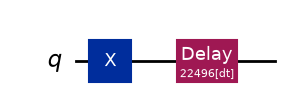

T2* (Ramsey) (measure X):


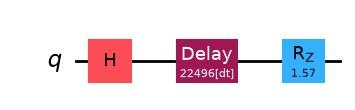

T2 (Hahn echo) (measure X):


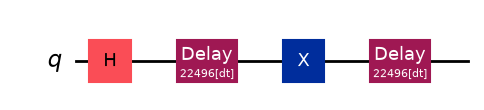

In [4]:
wait = int(5e-6 / dt) // granularity * granularity  # a wait of about 5 us
for name in ops.EXPERIMENTS:
    print(ops.NAMES[name], f"(measure {ops.OBSERVABLES[name]}):")
    fig = enc.build_circuit(name, wait, dt).draw("mpl")
    display(fig)
    plt.close(fig)  # keep the inline backend from drawing it a second time

The Ramsey circuit carries the programmed rotation `rz`, and the echo circuit has a flip `x` between two equal delays. Before a circuit runs, it is **transpiled** (compiled): rewritten into the gates that the device supports, with the qubit placed on a physical qubit. Transpiling can also run an **optimizer**, which simplifies the circuit by merging or removing gates when the result does the same thing. We switch the optimizer **off** (`transpile_for`). "Flip, wait, flip back" is what an optimizer is built to remove, and it would delete the very thing we want to measure.

## Stop and think: what did the encoding decide?

**Question 1.** Why is the wait the only thing that varies between the circuits of one experiment?

**Answer.** Then the curve is a clean function of $t$. Any other difference between circuits would mix a second effect into the curve.

**Question 2.** Why does the echo use half the delay in each wait?

**Answer.** The total time of the echo must be $t$, so that its curve compares with the other two at the same $t$. That is why `snap` takes `parts=2`.

**Question 3.** The Estimator on IBM devices can insert pulses into idle times automatically. Why do we switch that off here?

**Answer.** Those pulses are **dynamical decoupling**: flips inserted into idle time so that slow noise cancels, the same idea as the echo applied to every idle qubit. Here the idle time is the thing being measured, so the pulses would hide it. The notebook `dynamical_decoupling.ipynb` in this folder uses them on purpose.

## Step 3: Execution

Every delay of every experiment is one circuit, so three experiments of `points` delays each make $3 \times 41 = 123$ circuits with the default `points = 41`. They go out as one **job**, a batch of circuits sent to the device together. On hardware a job waits in a **queue** behind the jobs of other users, and that queue wait is paid once per job, not once per circuit.

On the simulator, the noise is added in three places:

1. every delay relaxes with the chosen $T_1$ and $T_2$;
2. the read-out flips the answer 2% or 4% of the time, depending on the state. A true value $v$ is read as $0.94\,v + 0.02$, because $1 - 0.02 - 0.04 = 0.94$ and $0.04 - 0.02 = 0.02$. This is what makes $A$ and $B$ differ from their ideal values;
3. the Ramsey and echo circuits run once for each of 256 frequency offsets, and the results are averaged. The offsets are drawn from a **Lorentzian** distribution: a bell-shaped curve with long tails, so a few offsets are large. Its width is set by $\gamma = 0.01$ rad per $\mu$s, the offset at which the curve falls to half its peak height. Each offset is constant during one run and different between runs, which is what slow noise does. This is why the echo can remove it and the Ramsey circuit cannot.

Why does averaging over offsets make a decay? One offset $\delta$ adds the phase $\delta t$, so the signal is $\cos(\delta t)$. At a given $t$, offsets of different size give cosines of different sign, and they cancel in the average. For small $t$ all the cosines are near 1 and the average is near 1. For a Lorentzian of half-width $\gamma$ the average of $\cos(\delta t)$ works out to $e^{-\gamma t}$, an exponential decay. The next cell checks it: at $t = 100\,\mu$s, $\gamma t = 1$, so the average should be $e^{-1} \approx 0.37$.

On hardware none of this is needed: the device has its own noise.

In [5]:
shifts = ops.slow_shifts()
t_check = 100.0  # us
print(
    f"average of cos(offset * t) at t = {t_check:.0f} us: {np.mean(np.cos(shifts * t_check)):.2f}"
)
print(
    f"exp(-gamma t) with gamma = {ops.GAMMA_SLOW}: {np.exp(-ops.GAMMA_SLOW * t_check):.2f}"
)

average of cos(offset * t) at t = 100 us: 0.38
exp(-gamma t) with gamma = 0.01: 0.37


In [6]:
data = execution.run(
    ops.EXPERIMENTS,
    t_max,
    points,
    backend_name,
    qubit,
    precision,
)
print(f"\nTotal time: {data['seconds']:.0f} s")

  123 circuits in one job

 (1 s)

Total time: 1 s


## Step 4: Analysis

### The fit

The fit is a least-squares fit: it picks the parameters that minimize the sum of the squared differences between the data and the model. `scipy.optimize.curve_fit` does this. It improves a guess step by step, so it needs a starting point, and a poor start can end at a poor answer. We therefore start from a guess read off the data: the amplitude from the first and last points, the time constant from a third of the longest delay (a guess of the right size), and the Ramsey frequency from the one we programmed.

The function also returns a **covariance matrix**: a table of how the errors of the fitted parameters move together. Its diagonal holds the squared standard errors, so the square root of a diagonal entry is the standard error of that parameter.

The first figure is T1. The upper panel shows the data, the fit, and a dotted line at $t = \tau$, where the curve has covered $1 - 1/e = 63\%$ of its path to the final value. The lower panel shows the **residuals**, data minus fit. If the model describes the physics, residuals scatter around zero with no pattern.

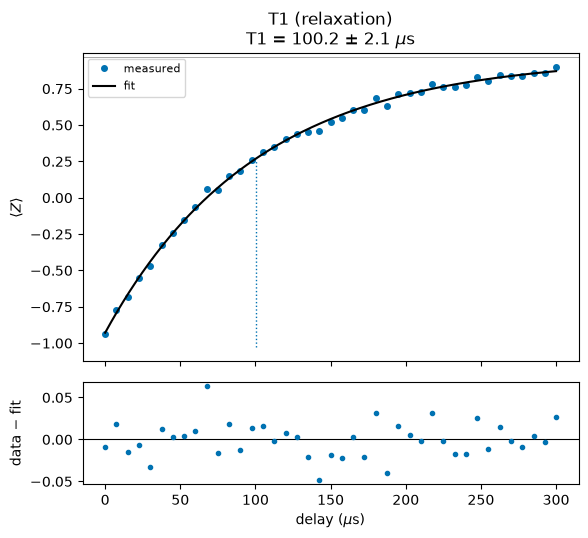

In [7]:
fits = analysis.fit_all(data)
analysis.plot_single("t1", data["experiments"]["t1"], fits["t1"]);

There are two ways to see what the fit does.

- **Left, a straight line.** Remove the fitted $A$ and $B$ from the data, and what is left is $e^{-t/\tau}$. Its logarithm is a straight line with slope $-1/\tau$. This was the method before computers. It is a good check but a poor way to *fit*. Every point has the same error of about 0.02 before the logarithm. After it, a point with a small value, say $0.05 \pm 0.02$, has an error of about $0.02/0.05 = 40\%$ in the logarithm, while a point near 1 has 2%. A straight-line fit treats them alike, and it cannot use points that scatter below zero at all.
- **Right, the cost.** The **cost** is the sum of squared residuals, the quantity the fit minimizes. The plot shows it as the time constant is varied by hand. The best fit is the lowest point. A narrow minimum means the data pin down $\tau$ tightly. A flat one means many values fit about equally well. The gray band is the standard error from the covariance matrix.

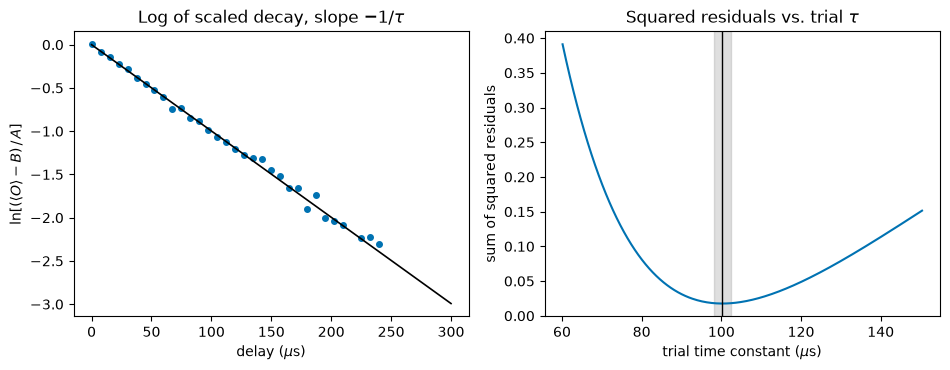

In [8]:
analysis.plot_checks("t1", data["experiments"]["t1"], fits["t1"]);

### T2\*: the Ramsey fringes

Now the phase. The curve oscillates at the detuning we programmed, 50 kHz, so one period is $1/(50\text{ kHz}) = 20\,\mu$s. The envelope (dashed) is the decay we want, $e^{-t/T_2^*}$, and the oscillation inside it is there to prove that phase is evolving. The fit has five parameters: the amplitude $A$, the time constant $\tau$, the fringe frequency $f$, the starting phase $\phi$, and the offset $B$. A fit with a cosine is more sensitive to its starting guess than the others, which is why we start the frequency at the value we programmed.

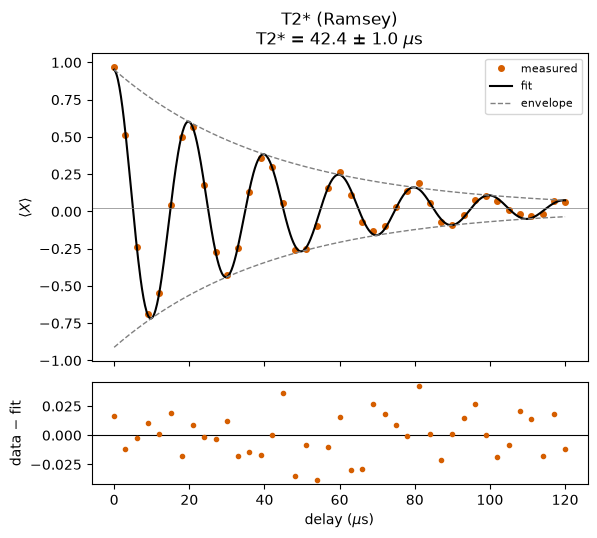

In [9]:
analysis.plot_single("t2star", data["experiments"]["t2star"], fits["t2star"]);

### T2: the Hahn echo

The same state, a flip in the middle of the wait. The oscillation is gone, because the programmed detuning and everything else constant is refocused, and what is left is a plain decay. Its time is longer than T2\*, because the slow noise no longer counts.

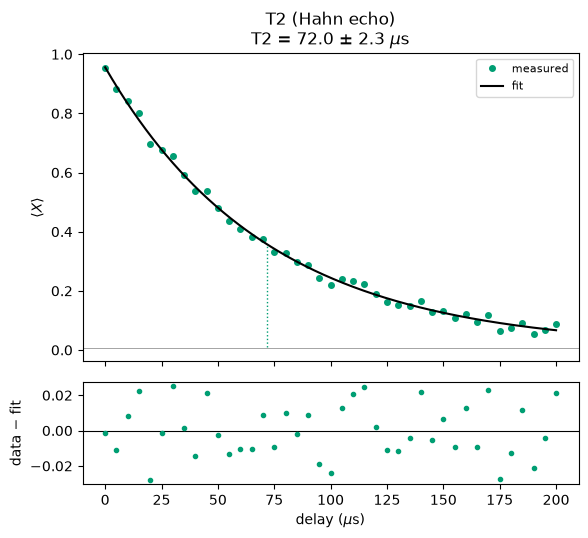

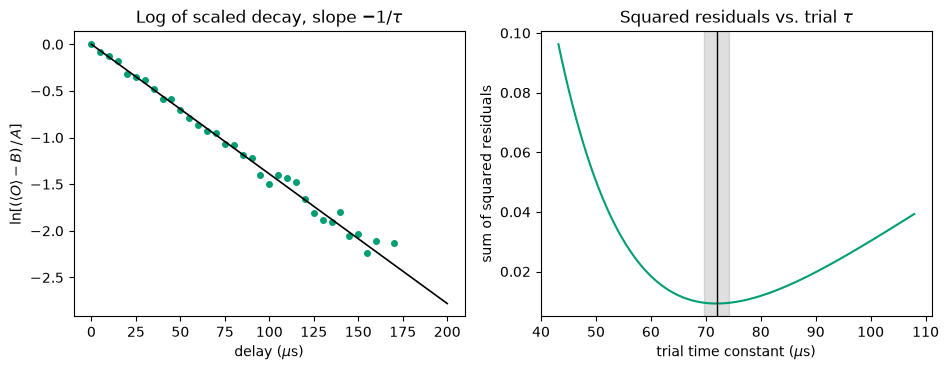

In [10]:
analysis.plot_single("t2", data["experiments"]["t2"], fits["t2"])
analysis.plot_checks("t2", data["experiments"]["t2"], fits["t2"]);

### All three together

The table lists the fitted times with their standard errors. On the simulator it also shows the times that were built in, so the fit can be checked. $T_2^*$ is not one of the inputs of the noise model. It follows from the echo time and the slow noise as $1/T_2^* = 1/T_2 + \gamma$, with $\gamma = 0.01\,\mu\text{s}^{-1}$ from Step 3. Here is where the rule comes from. The Ramsey signal has two decays that multiply. One is $e^{-t/T_2}$, the part the echo also sees. The other is the average of the fringes over the slow offsets, $e^{-\gamma t}$ (Step 3). The product is $e^{-t(1/T_2 + \gamma)}$, and its exponent is $-t/T_2^*$. Numeric check: $1/70 + 0.01 = 0.0243\,\mu\text{s}^{-1}$, so $T_2^* = 41.2\,\mu$s, the built-in value.

                         fit (us)  built in (us)  amplitude
T1 (relaxation)      100.2 +/- 2.1           100.0      -1.89
T2* (Ramsey)          42.4 +/- 1.0            41.2       0.93
T2 (Hahn echo)        72.0 +/- 2.3            70.0       0.95

Ramsey fringe frequency: 50.0 kHz (programmed: 50.0 kHz)


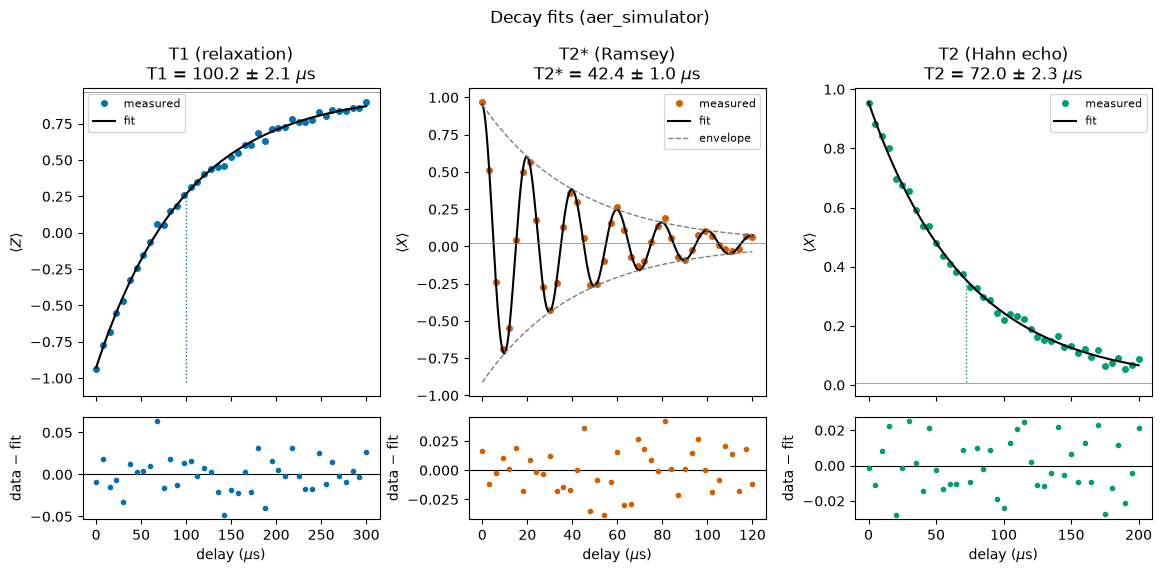

In [11]:
analysis.print_table(data, fits)
fig = analysis.plot_fits(data, fits)

The pure dephasing time $T_\varphi$ is the part of the phase loss that does not come from energy loss. It follows from the three numbers, in two steps.

1. **Energy loss alone.** A superposition needs both $|0\rangle$ and $|1\rangle$. The population of $|1\rangle$ decays as $e^{-t/T_1}$. Population is the square of an amplitude, so the amplitude of $|1\rangle$ decays as $e^{-t/(2T_1)}$, and the phase signal shrinks at rate $1/(2T_1)$ even if nothing else happens.
2. **Independent decays multiply, so their rates add.** The phase signal also shrinks because of pure dephasing, at a rate $1/T_\varphi$. Two independent decays $e^{-at}$ and $e^{-bt}$ multiply to $e^{-(a+b)t}$. So

$$\frac{1}{T_2} = \frac{1}{2T_1} + \frac{1}{T_\varphi}.$$

A rate cannot be negative, so $1/T_\varphi \ge 0$, which gives $1/T_2 \ge 1/(2T_1)$, that is $T_2 \le 2T_1$. This is the second inequality promised under [The problem](#the-problem). Numeric check with the built-in times: $1/70 - 1/200 = 0.0093\,\mu\text{s}^{-1}$, so $T_\varphi \approx 108\,\mu$s. The number tells you how much a qubit would gain if its relaxation could be improved (not much when $T_\varphi$ is the smaller number) and how much would not change.

The next cell computes $T_\varphi$ from the fits. The error propagation works like this. The standard error of $1/T_2$ is $\sigma_{T_2}/T_2^2$, and likewise for $1/(2T_1)$. These two errors are independent, so they add in quadrature, and `np.hypot(a, b)` is $\sqrt{a^2+b^2}$. The range of $T_\varphi$ comes from inverting the rate plus and minus its error. The `max(..., 1e-9)` guard stops the division when the lower end of the rate reaches zero, which would make the upper end of $T_\varphi$ infinite.

In [12]:
tau = {name: fits[name]["params"]["tau"] for name in fits}
err = {name: fits[name]["errors"]["tau"] for name in fits}

rate = 1 / tau["t2"] - 1 / (2 * tau["t1"])
rate_err = np.hypot(err["t2"] / tau["t2"] ** 2, err["t1"] / (2 * tau["t1"] ** 2))
print(
    f"T2* = {tau['t2star']:.1f} us <= T2 = {tau['t2']:.1f} us <= 2 T1 = {2 * tau['t1']:.1f} us"
)
print(
    f"pure dephasing time T_phi = {1 / rate:.0f} us "
    f"(1 sigma range {1 / (rate + rate_err):.0f} to {1 / max(rate - rate_err, 1e-9):.0f} us)"
)

T2* = 42.4 us <= T2 = 72.0 us <= 2 T1 = 200.5 us
pure dephasing time T_phi = 112 us (1 sigma range 107 to 118 us)


## Reading the results

The numbers below are for the simulator with the default settings. The noise is random and not seeded, so your numbers differ from run to run by about their standard errors.

- **T1 is about 100 $\mu$s.** A fit typically lands within 2 standard errors of the built-in value. Roughly one run in twenty lands further away, and that is the statistics of a standard error, not a fault. The fitted amplitude is about $-1.9$. The ideal $-2$ is scaled by the read-out factor 0.94 from Step 3, and the fit puts that into $A$ and $B$ and leaves $\tau$ alone. The curve goes from about $-1$ to about $+1$ as the qubit falls from $|1\rangle$ to $|0\rangle$. The residuals scatter by about 0.02, the precision we asked for.
- **T2\* is about 41 $\mu$s.** The fringes sit at 50 kHz, and the envelope decays about 1.7 times as fast as the echo does ($70/41 \approx 1.7$).
- **T2 is about 70 $\mu$s.** The echo removed the slow noise, so the time is longer. This is the time you would expect a qubit to keep a superposition if you protect it with a flip.
- **The ordering holds**: $T_2^* < T_2 < 2T_1$, where $2T_1$ is about 200 $\mu$s (the printed fitted value moves with the T1 fit). A fit that gives $T_2 > 2T_1$ would mean something is wrong with the measurement: a bad delay range, a fit that stopped at a poor value, or drift in the qubit between the experiments.
- **The simulator agrees with its own inputs** to within a few standard errors. A few percent is the accuracy of an experiment with 41 points and a precision of 0.02. A smaller error needs more points or more shots. It is also limited by the length of the delay range (see item 1 under *What to try next*).

On hardware, expect more of the following:

- **A smaller $|A|$ and a $B$ away from its ideal value**, because the preparation and read-out are imperfect. These errors do not grow with the delay, so the fit puts them in $A$ and $B$ and leaves $\tau$ alone.
- **A Ramsey frequency that differs from 50 kHz**, by the offset between the qubit's true frequency and the one the electronics assume.
- **T1 that changes from hour to hour.** The time is set by a few defects in the material, which move. Two measurements a day apart may not agree, and that is real.
- **A decay that is not exponential**, which shows up as structure in the residuals. The Lorentzian offsets used here give an exponential Ramsey decay. Real slow noise often has a bell-shaped distribution without long tails (a Gaussian), and averaging $\cos(\delta t)$ over it gives a **Gaussian-shaped decay**, $e^{-(t/T)^2}$, which starts flat and then falls faster than an exponential.

## What to try next

1. Change `t_max["t1"]` to `100.0` (one $T_1$) and then to `30.0`. How do the fitted $T_1$ and its error change? A curve that runs for only one $\tau$ has covered only 63% of its way to the final value. A larger $B$ with a longer $\tau$ then gives almost the same curve, so the fit cannot tell $\tau$ from $B$, and the error of $\tau$ grows. What does this say about choosing a delay range?
2. Set `points = 11`, then `101`. How does the standard error scale? Is it worth the extra circuits?
3. Set `precision = 0.1`, then `0.005`. Which gets the better error bar for the same number of circuits, more points or a smaller precision? (The simulator is fast enough to try.)
4. In `ops.py` change `GAMMA_SLOW` to `1 / 30` and rerun. Predict what happens to T2\* and to T2 first, using $1/T_2^* = 1/T_2 + \gamma$.
5. Change `SIM_T2` to a value larger than `2 * SIM_T1`. Predict what happens, using the inequality derived in Step 4, and then try it.
6. Change `DETUNING` in `ops.py` to `0.5` (MHz) and rerun. The period is now 2 $\mu$s, and the delays are spaced about 3 $\mu$s apart, so the fringes are faster than the spacing of the delays. What does the fit return? A fast oscillation sampled too sparsely looks like a slow one. This effect is called aliasing.
7. Run on `ibm_rensselaer` with `qubit = 0`, then with a different qubit. Do the qubits agree? Compare with the T1 and T2 values on the backend's calibration page. Which of your numbers is closest, and why might the page differ from your measurement?
8. Run T1 three times in a row on hardware and compare the results. How big is the spread compared with the standard error of one fit?
9. A superposition lives for $T_2$, but an algorithm runs many gates. Suppose a circuit has 200 gates and each gate takes 0.05 $\mu$s (a typical order of magnitude for a single-qubit gate). How long does the circuit run? With $T_2 = 70\,\mu$s, what fraction $e^{-t/T_2}$ of the phase signal is left at the end?

## Terms

| Term | Plain definition | First used |
|---|---|---|
| Calibration page | Web page listing measured times and errors for each qubit of a device | The problem |
| T1 | Time for a qubit in $\lvert1\rangle$ to fall to $\lvert0\rangle$ (decay time of the bit) | The problem |
| Qubit frequency | Energy difference of $\lvert1\rangle$ and $\lvert0\rangle$ as a frequency; sets how fast the phase grows | The problem |
| Ramsey experiment | Prepare $\lvert+\rangle$, wait, measure $\langle X\rangle$ | The problem |
| T2\* | Decay time of the Ramsey signal (all dephasing) | The problem |
| T2 | Decay time of the echo signal (fast noise and energy loss only) | The problem |
| Hahn echo | Wait, flip, wait again; cancels constant phase errors | Step 1 |
| Aer simulator | Program that mimics a noisy quantum device | Setup |
| Read-out error | Chance that a measured 0 or 1 is wrong (here 2% and 4%) | Setup |
| Shot | One run of a circuit, giving one $\pm1$ answer | Setup |
| Standard error | Typical random scatter of an estimate around its true value | Setup |
| Decay time, $\tau$ | Time for the decaying part to fall to $1/e$ | Setup, Step 1 |
| Detuning, $f$ | Frequency offset we program on purpose in the Ramsey circuit | Step 1 |
| `rz`$(a)$ | Gate that adds the phase $a$ to $\lvert1\rangle$ relative to $\lvert0\rangle$ | Step 1 |
| Nuisance parameter | Fit parameter needed by the model but not wanted ($A$, $B$) | Step 1 |
| Fringes, envelope | Oscillation of the Ramsey signal, and the smooth decay its peaks follow | Step 1 |
| Refocused | Phase spread undone by the echo | Step 1 |
| dt, granularity | Tick of the control clock, and the block size delays must be a multiple of | Step 2 |
| Transpile, optimizer | Rewrite a circuit into supported gates, and simplify it | Step 2 |
| Dynamical decoupling | Flips inserted in idle time so slow noise cancels | Step 2 |
| Job, queue wait | A batch of circuits sent together, and the wait behind other users | Step 3 |
| Lorentzian | Bell-shaped distribution with long tails | Step 3 |
| Covariance matrix | Table of how parameter errors move together; diagonal is the squared standard errors | Step 4 |
| Residual, cost | Data minus fit, and the sum of their squares | Step 4 |
| $T_\varphi$ | Pure dephasing time, from $1/T_2 = 1/(2T_1) + 1/T_\varphi$ | Step 4 |
| Aliasing | A fast oscillation sampled too sparsely looks slow | What to try next |